<a href="https://colab.research.google.com/github/navyashreenavy/PADV/blob/main/PADV_10_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import cross_val_predict

In [2]:
data = {
"Temperature": [
30, 32, 28, 25, 22, 20, 18, 27, 31, 24,
29, 21, 19, 26, 33, 23, 17, 28, 30, 22,
25, 32, 18, 27, 24, 31, 20, 29, 23, 26
],
"Humidity": [
40, 35, 75, 80, 85, 90, 92, 60, 38, 78,
45, 88, 95, 65, 30, 82, 96, 55, 42, 86,
72, 33, 93, 58, 76, 37, 91, 48, 84, 62
],
"Wind_Speed": [
10, 12, 20, 25, 18, 22, 28, 15, 11, 21,
13, 24, 30, 17, 9, 19, 32, 14, 12, 26,
23, 10, 29, 16, 20, 11, 27, 13, 25, 18
],
"Weather": [
"Sunny", "Sunny", "Rainy", "Rainy", "Rainy",
"Rainy", "Rainy", "Cloudy", "Sunny", "Rainy",
"Sunny", "Rainy", "Rainy", "Cloudy", "Sunny",
"Rainy", "Rainy", "Cloudy", "Sunny", "Rainy",
"Cloudy", "Sunny", "Rainy", "Cloudy", "Rainy",
"Sunny", "Rainy", "Sunny", "Rainy", "Cloudy"
]
}

In [3]:
df = pd.DataFrame(data)

print("WEATHER DATASET")
print(df.head(10))
print("\nDataset Shape:", df.shape)

WEATHER DATASET
   Temperature  Humidity  Wind_Speed Weather
0           30        40          10   Sunny
1           32        35          12   Sunny
2           28        75          20   Rainy
3           25        80          25   Rainy
4           22        85          18   Rainy
5           20        90          22   Rainy
6           18        92          28   Rainy
7           27        60          15  Cloudy
8           31        38          11   Sunny
9           24        78          21   Rainy

Dataset Shape: (30, 4)


In [4]:
model = DecisionTreeClassifier(random_state=42)

In [6]:
# Define features (X) and target (y) from the dataframe
X = df[["Temperature", "Humidity", "Wind_Speed"]]
y = df["Weather"]

kfold = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

scores = cross_val_score(
    model, X, y, cv=kfold, scoring="accuracy"
)

print("Cross-validation Accuracies:", scores)
print("Mean Accuracy:", scores.mean())

Cross-validation Accuracies: [0.83333333 1.         1.         1.         0.83333333]
Mean Accuracy: 0.9333333333333333


In [8]:
print("\nK-FOLD CROSS-VALIDATION RESULTS")

for i, score in enumerate(scores, start=1):
    print(f"Fold {i} Accuracy: {score:.2f}")

print("\nAverage Accuracy:", round(scores.mean(), 2))
print("Standard Deviation:", round(scores.std(), 2))


K-FOLD CROSS-VALIDATION RESULTS
Fold 1 Accuracy: 0.83
Fold 2 Accuracy: 1.00
Fold 3 Accuracy: 1.00
Fold 4 Accuracy: 1.00
Fold 5 Accuracy: 0.83

Average Accuracy: 0.93
Standard Deviation: 0.08


In [9]:
y_pred = cross_val_predict(model, X, y, cv=kfold)

In [10]:
print("\nCONFUSION MATRIX")
print(confusion_matrix(y, y_pred, labels=["Cloudy", "Rainy", "Sunny"]))


CONFUSION MATRIX
[[ 4  1  1]
 [ 0 15  0]
 [ 0  0  9]]


In [11]:
print("\nCLASSIFICATION REPORT")
print(classification_report(y, y_pred, zero_division=0))


CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Cloudy       1.00      0.67      0.80         6
       Rainy       0.94      1.00      0.97        15
       Sunny       0.90      1.00      0.95         9

    accuracy                           0.93        30
   macro avg       0.95      0.89      0.91        30
weighted avg       0.94      0.93      0.93        30



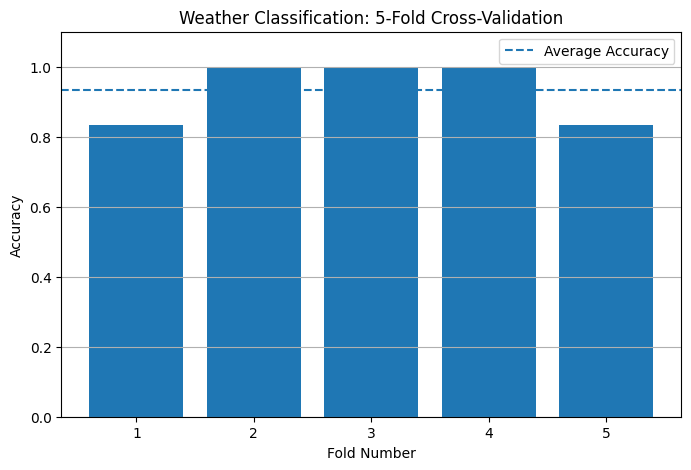


RESULT: K-fold cross-validation and model performance analysis completed successfully.


In [12]:
plt.figure(figsize=(8, 5))

plt.bar(range(1, 6), scores)
plt.axhline(
scores.mean(),
linestyle="--",
label="Average Accuracy"
)

plt.xlabel("Fold Number")
plt.ylabel("Accuracy")
plt.title("Weather Classification: 5-Fold Cross-Validation")
plt.xticks(range(1, 6))
plt.ylim(0, 1.1)
plt.legend()
plt.grid(axis="y")
plt.show()

print("\nRESULT: K-fold cross-validation and model performance analysis completed successfully.")